# Lab 6 — CP9: ABG Rebuild and Oracle Full Base Model

**Company A:** Oracle (ORCL) · **Company B:** Microsoft (MSFT) · **Units:** USD millions except shares, percentages, and per-share values.

This is a separate Tuesday workbook. It reads the SEC-backed company data from the prework workbook, rather than duplicating filing reads. The model follows the required order: income statement; driver-led balance sheet; FCFE; cash last; check block; valuation gated by checks and `g < r`.

**AI disclosure:** I used an AI coding partner to assemble and test this notebook from the SEC-backed prework. I must independently verify the sources, mappings, assumptions, formulas, and outputs before submission. Edition A must be written in class without AI.

In [1]:
from __future__ import annotations
from copy import deepcopy
from datetime import date
from pathlib import Path
import os, json, nbformat, pandas as pd
pd.options.display.float_format=lambda x: f"{x:,.2f}"
LAB=Path.cwd() if Path("Lab6_Oracle_Microsoft_Prework.ipynb").exists() else Path("lab6")
assert (LAB/"Lab6_Oracle_Microsoft_Prework.ipynb").exists()
assert (LAB/"cache"/"oracle_2025_10k.htm").exists()
print(f"Run date: {date.today():%Y-%m-%d}; lab folder: {LAB.resolve()}")

Run date: 2026-10-01; lab folder: /Users/douglasbuckeridge/Documents/Courses/PythonFinance2026/DouglasBuckeridge/lab6


## Primary and secondary sources

The cached SEC Forms 10-K are the controlling primary evidence. The next cell is an actual WRDS / Compustat annual-fundamentals pull. It prompts only for a WRDS username in an interactive kernel, then uses WRDS’s normal authentication. It saves the returned data and an audit record to `lab6/outputs/`; SEC filed data continue to control any disagreement.

In [2]:
def pull_wrds():
    status={"run_date":date.today().isoformat(),"source":"WRDS / Compustat comp.funda","status":None,"detail":None}
    out=LAB/"outputs"; out.mkdir(exist_ok=True); username=os.getenv("WRDS_USERNAME")
    if not username:
        try: username=input("WRDS username (Enter to record pending): ").strip()
        except Exception: username=""
    if not username:
        data=pd.DataFrame(); status.update(status="pending",detail="No WRDS username supplied; rerun this cell interactively.")
    else:
        try:
            import wrds
            conn=wrds.Connection(wrds_username=username)
            sql="""select gvkey, datadate, fyear, tic, revt, oiadp, ni, at, lt, ceq, capx, ppent, invt, dlc, dltt, che from comp.funda where tic in ('ORCL','MSFT') and indfmt='INDL' and datafmt='STD' and popsrc='D' and consol='C' and fyear between 2023 and 2025 order by tic, datadate"""
            data=conn.raw_sql(sql,date_cols=["datadate"]); conn.close(); data.to_csv(out/"wrds_compustat_funda_orcl_msft.csv",index=False)
            status.update(status="retrieved",detail=f"Retrieved {len(data)} annual rows.")
        except Exception as exc:
            data=pd.DataFrame(); status.update(status="failed",detail=f"{type(exc).__name__}: {exc}")
    pd.DataFrame([status]).to_csv(out/"wrds_compustat_attempt.csv",index=False)
    return status,data
wrds_status,wrds_funda=pull_wrds(); display(pd.DataFrame([wrds_status]));
if not wrds_funda.empty: display(wrds_funda)
else: print("No Compustat value has been substituted for the SEC model inputs.")

WRDS recommends setting up a .pgpass file.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done


,run_date,source,status,detail
0,2026-10-01,WRDS / Compustat comp.funda,retrieved,Retrieved 6 annual rows.


,gvkey,datadate,fyear,tic,revt,oiadp,ni,at,lt,ceq,capx,ppent,invt,dlc,dltt,che
0,012141,2023-06-30,2023,MSFT,"211,915.00","89,694.00","72,361.00","411,976.00","205,753.00","206,223.00","28,107.00","109,987.00","2,500.00","8,853.00","70,588.00","111,262.00"
1,012141,2024-06-30,2024,MSFT,"245,122.00","109,433.00","88,136.00","512,163.00","243,686.00","268,477.00","44,477.00","154,552.00","1,246.00","14,871.00","82,981.00","75,543.00"
2,012141,2025-06-30,2025,MSFT,"281,724.00","128,528.00","101,832.00","619,003.00","275,524.00","343,479.00","64,551.00","229,789.00",938.00,"11,595.00","100,589.00","94,565.00"
3,012142,2024-05-31,2023,ORCL,"52,961.00","15,745.00","10,467.00","140,976.00","131,737.00","8,704.00","6,866.00","28,836.00",334.00,"11,905.00","82,564.00","10,661.00"
4,012142,2025-05-31,2024,ORCL,"57,399.00","17,951.00","12,443.00","168,361.00","147,392.00","20,451.00","21,215.00","56,667.00",303.00,"9,442.00","99,533.00","11,203.00"
5,012142,2026-05-31,2025,ORCL,"67,357.00","22,444.00","17,087.00","261,759.00","218,703.00","37,554.00","55,663.00","129,647.00",<NA>,"11,361.00","156,071.00","31,894.00"


## Company half — SEC-filed history from prework

Only prework’s data-definition cells are evaluated. This preserves the separate company/method halves and avoids a new hand transcription.

In [3]:
prework=nbformat.read(LAB/"Lab6_Oracle_Microsoft_Prework.ipynb",as_version=4); scope={"pd":pd}
for cell in prework.cells:
    if cell.cell_type=="code" and any(x in cell.source for x in ("oracle = pd.DataFrame","microsoft = pd.DataFrame","filing_only = pd.DataFrame")): exec(cell.source,scope)
oracle,microsoft,filing_only=scope["oracle"].copy(),scope["microsoft"].copy(),scope["filing_only"].copy()
display(oracle); assert oracle.loc[2025,"revenue"]==57399 and oracle.loc[2025,"net_income"]==12443

,start,end,days,accession,filed,revenue,cost_of_revenue,gross_profit_derived,operating_expenses_below_gross_profit,operating_income,...,income_tax,net_income,depreciation_and_amortization,operating_cash_flow,capital_expenditure,inventory,ppe_net,total_assets,total_liabilities,shareholders_equity
fiscal_year,,,,,,,,,,,,,,,,,,,,,
2023,2022-06-01,2023-05-31,365,0000950170-23-028914,2023-06-20,49954,13564,36390,23297,13093,...,623,8503,6108,17165,8695,298,17069,134384,133311,1073
2024,2023-06-01,2024-05-31,366,0000950170-24-075605,2024-06-20,52961,15143,37818,22465,15353,...,1274,10467,6139,18673,6866,334,21536,140976,132272,8704
2025,2024-06-01,2025-05-31,365,0000950170-25-087926,2025-06-18,57399,16927,40472,22794,17678,...,1717,12443,6174,20821,21215,303,43522,168361,147910,20451


,start,end,days,accession,filed,revenue,cost_of_revenue,gross_profit,operating_expenses,operating_income,...,income_tax,net_income,depreciation_and_amortization,operating_cash_flow,capital_expenditure,inventory,ppe_net,total_assets,total_liabilities,shareholders_equity
fiscal_year,,,,,,,,,,,,,,,,,,,,,
2023,2022-07-01,2023-06-30,365,0000950170-23-035122,2023-07-27,211915,65863,146052,57529,88523,...,16950,72361,11000,87582,28107,2500,95641,411976,205753,206223
2024,2023-07-01,2024-06-30,366,0000950170-24-087843,2024-07-30,245122,74114,171008,61575,109433,...,19651,88136,15200,118548,44477,1246,135591,512163,243686,268477
2025,2024-07-01,2025-06-30,365,0000950170-25-100235,2025-07-30,281724,87831,193893,65365,128528,...,21795,101832,22000,136162,64551,938,204966,619003,275524,343479


,company,item,value,as_of_or_period,statement_or_cover,accession,filed
0,Oracle,Capital expenditure,"21,215",FY ended 2025-05-31,"2025 Form 10-K, Consolidated Statements of Cas...",0000950170-25-087926,2025-06-18
1,Oracle,Cash and cash equivalents,"10,786",2025-05-31,"2025 Form 10-K, Consolidated Balance Sheets",0000950170-25-087926,2025-06-18
2,Oracle,Total debt (current + non-current),"92,568 = 7,271 + 85,297",2025-05-31,"2025 Form 10-K, Consolidated Balance Sheets: N...",0000950170-25-087926,2025-06-18
3,Oracle,Latest cover share count,"3,023,736,000 shares",2026-09-07,2026 Q1 Form 10-Q cover,0001193125-26-389274,2026-09-11
4,Microsoft,Capital expenditure,"64,551",FY ended 2025-06-30,"2025 Form 10-K, Consolidated Statements of Cas...",0000950170-25-100235,2025-07-30
5,Microsoft,Cash and cash equivalents,"30,242",2025-06-30,"2025 Form 10-K, Consolidated Balance Sheets",0000950170-25-100235,2025-07-30
6,Microsoft,Total debt (current + non-current),"41,787 = 1,635 + 40,152",2025-06-30,"2025 Form 10-K, Consolidated Balance Sheets",0000950170-25-100235,2025-07-30
7,Microsoft,Latest cover share count,"7,425,545,491 shares",2026-07-23,2026 Form 10-K cover,0001193125-26-323660,2026-07-29


,start,end,days,accession,filed,revenue,cost_of_revenue,gross_profit_derived,operating_expenses_below_gross_profit,operating_income,...,income_tax,net_income,depreciation_and_amortization,operating_cash_flow,capital_expenditure,inventory,ppe_net,total_assets,total_liabilities,shareholders_equity
fiscal_year,,,,,,,,,,,,,,,,,,,,,
2023,2022-06-01,2023-05-31,365,0000950170-23-028914,2023-06-20,49954,13564,36390,23297,13093,...,623,8503,6108,17165,8695,298,17069,134384,133311,1073
2024,2023-06-01,2024-05-31,366,0000950170-24-075605,2024-06-20,52961,15143,37818,22465,15353,...,1274,10467,6139,18673,6866,334,21536,140976,132272,8704
2025,2024-06-01,2025-05-31,365,0000950170-25-087926,2025-06-18,57399,16927,40472,22794,17678,...,1717,12443,6174,20821,21215,303,43522,168361,147910,20451


## Step 1 — ABG known answer

The classroom ABG half is retained solely to test the reusable method against the deck’s $291.75 and 79.8% terminal-share known answer.

In [4]:
ABG={"opening_year":2025,"opening":{"revenue":17999.,"inventory":2135.8,"ppe":3070.4,"cash":40.4,"floor_plan":2027.,"debt":3572.,"revolver":0.,"equity":3891.7,"other_assets":6371.6,"other_liabilities":2127.5},"drivers":{"growth":.018,"gm":.1705,"sga":[.665,.655,.645,.645,.645],"da":.0268,"noncash":120.,"capex":250.,"tax":.255,"days":52.2,"fp_pct":.949,"owc":.008,"fp_rate":.0467,"debt_rate":.0544,"rev_rate":.06,"rev_cap":850.,"floor":25.,"paydown":150.,"buyback":150.},"valuation":{"r":.10,"g":.025,"shares":17951349}}
def project_abg(c,years=5,cash_override=None):
 d,p,rows=c["drivers"],deepcopy(c["opening"]),[]
 for n in range(years):
  y=c["opening_year"]+n+1; rev=p["revenue"]*(1+d["growth"]); gp=rev*d["gm"]; cogs=rev-gp; da=p["ppe"]*d["da"]; sga=gp*d["sga"][n]; ebit=gp-sga-da-d["noncash"]; interest=p["floor_plan"]*d["fp_rate"]+p["debt"]*d["debt_rate"]+p["revolver"]*d["rev_rate"]; tax=(ebit-interest)*d["tax"]; ni=(ebit-interest)-tax
  inv=cogs*d["days"]/365; fp=inv*d["fp_pct"]; ppe=p["ppe"]+d["capex"]-da; debt=p["debt"]-d["paydown"]; owc=d["owc"]*(rev-p["revenue"]); other_assets=p["other_assets"]+owc-d["noncash"]; equity=p["equity"]+ni-d["buyback"]
  fcfe=ni+da+d["noncash"]-d["capex"]-(inv-p["inventory"])-owc+(fp-p["floor_plan"])-d["paydown"]; before=p["cash"]+fcfe-d["buyback"]; draw=max(0.,d["floor"]-before); revolver=p["revolver"]+draw
  if revolver>d["rev_cap"]: raise ValueError(f"{y}: revolver cap exceeded")
  expected=before+draw; cash=(cash_override or {}).get(y,expected); rows.append(dict(year=y,revenue=rev,gross_profit=gp,cogs=cogs,sga=sga,depreciation_and_amortization=da,noncash=d["noncash"],ebit=ebit,interest=interest,tax=tax,net_income=ni,inventory=inv,floor_plan=fp,ppe=ppe,debt=debt,equity=equity,fcfe=fcfe,cash=cash,expected_cash=expected,cash_floor=d["floor"],revolver=revolver,total_assets=inv+ppe+cash+other_assets,total_liabilities=fp+debt+revolver+p["other_liabilities"]))
  p=dict(revenue=rev,inventory=inv,ppe=ppe,cash=cash,floor_plan=fp,debt=debt,revolver=revolver,equity=equity,other_assets=other_assets,other_liabilities=p["other_liabilities"])
 return pd.DataFrame(rows).set_index("year")
def checks(p,tolerance=.1):
 q=pd.DataFrame(index=p.index); q["balance_residual"]=p.total_assets-p.total_liabilities-p.equity; q["cash_tie_residual"]=p.cash-p.expected_cash; q["cash_minus_floor"]=p.cash-p.cash_floor; q["pass"]=q.balance_residual.abs().le(tolerance)&q.cash_tie_residual.abs().le(tolerance)&q.cash_minus_floor.ge(-tolerance); return q
def valuation(c,p):
 r,g=c["valuation"]["r"],c["valuation"]["g"]
 if g>=r: raise ValueError("Valuation refused: terminal growth must be below discount rate.")
 if not checks(p)["pass"].all(): raise ValueError("Valuation refused: check block failed.")
 pv=sum(x/(1+r)**i for i,x in enumerate(p.fcfe,1)); pvt=(p.fcfe.iloc[-1]+c["drivers"]["paydown"])*(1+g)/(r-g)/(1+r)**len(p); eq=pv+pvt; share_count=c["valuation"]["shares"]*(1e6 if c["valuation"].get("shares_are_millions",False) else 1); return {"equity_value":eq,"value_per_share":eq*1e6/share_count,"terminal_share":pvt/eq}
abg=project_abg(ABG); abgv=valuation(ABG,abg); display(abg[["revenue","gross_profit","cogs","sga","depreciation_and_amortization","ebit","interest","tax","net_income","inventory","floor_plan","ppe","debt","equity","fcfe","cash","revolver"]]); display(checks(abg)); print(f"ABG: ${abgv['value_per_share']:,.2f}/share; terminal share {abgv['terminal_share']:.1%}"); assert checks(abg)["pass"].all() and abs(abgv["value_per_share"]-291.75)<1 and abs(abgv["terminal_share"]-.798)<.003

,revenue,gross_profit,cogs,sga,depreciation_and_amortization,ebit,interest,tax,net_income,inventory,floor_plan,ppe,debt,equity,fcfe,cash,revolver
year,,,,,,,,,,,,,,,,,
2026,"18,322.98","3,124.07","15,198.91","2,077.51",82.29,844.28,288.98,141.60,413.70,"2,173.65","2,062.80","3,238.11","3,422.00","4,155.40",211.34,101.74,0.00
2027,"18,652.80","3,180.30","15,472.49","2,083.10",86.78,890.42,282.49,155.02,452.91,"2,212.78","2,099.93","3,401.33","3,272.00","4,458.31",255.06,206.79,0.00
2028,"18,988.55","3,237.55","15,751.00","2,088.22",91.16,938.17,276.06,168.84,493.27,"2,252.61","2,137.73","3,560.18","3,122.00","4,801.58",299.71,356.50,0.00
2029,"19,330.34","3,295.82","16,034.52","2,125.81",95.41,954.60,269.67,174.66,510.28,"2,293.16","2,176.20","3,714.76","2,972.00","5,161.86",320.89,527.39,0.00
2030,"19,678.29","3,355.15","16,323.14","2,164.07",99.56,971.52,263.31,180.60,527.62,"2,334.43","2,215.38","3,865.21","2,822.00","5,539.48",342.29,719.68,0.00


,balance_residual,cash_tie_residual,cash_minus_floor,pass
year,,,,
2026,0.00,0.00,76.74,True
2027,0.00,0.00,181.79,True
2028,0.00,0.00,331.50,True
2029,0.00,0.00,502.39,True
2030,0.00,0.00,694.68,True


ABG: $291.75/share; terminal share 79.8%


## Step 2 — Oracle: history, inputs, and no `NaN` display

The first year has no preceding year, so growth is displayed as `—`, not `NaN`. Oracle’s filed direct costs are Cloud services/license support, Hardware, and Services. Its operating-cost subtotal includes D&A; the model separates D&A from that subtotal and therefore deducts it exactly once.

Forecast inputs are explicitly labeled. History inputs use FY2024–25 values. Debt repayment, buyback, cash floor, cost of equity, and terminal growth are provisional judgments and require evidence before Exercise 4.

In [5]:
def history(a):
 h=pd.DataFrame(index=a.index); h["revenue growth"]=a.revenue.pct_change(); h["gross margin"]=1-a.cost_of_revenue/a.revenue; h["cash costs / revenue"]=(a.operating_expenses_below_gross_profit-a.depreciation_and_amortization)/a.revenue; h["D&A / revenue"]=a.depreciation_and_amortization/a.revenue; h["tax / pretax"]=a.income_tax/a.pretax_income; h["capex / revenue"]=a.capital_expenditure/a.revenue; h["inventory / revenue"]=a.inventory/a.revenue; return h
oh=history(oracle); display(oh.map(lambda x:"—" if pd.isna(x) else f"{x:.1%}"))
avg=lambda col:float(oh.loc[2024:2025,col].mean()); z=oracle.loc[2025]
facts=json.load(open(LAB/"cache"/"CIK0001341439_companyfacts.json"))["facts"]["us-gaap"]
def fact_2025(tag):
 rows=facts[tag]["units"]["USD"]
 return next(x["val"]/1e6 for x in reversed(rows) if x.get("end")=="2025-05-31" and x.get("form")=="10-K")
current_assets,current_liabilities,current_debt=map(fact_2025,["AssetsCurrent","LiabilitiesCurrent","DebtCurrent"])
nwc=(current_assets-10786.)-(current_liabilities-current_debt) # operating current assets less operating current liabilities; excludes cash and debt
ORACLE={"name":"Oracle","opening_year":2025,"opening":{"revenue":z.revenue,"inventory":z.inventory,"ppe":z.ppe_net,"cash":10786.,"debt":92568.,"equity":z.shareholders_equity,"assets":z.total_assets,"liabilities":z.total_liabilities},"drivers":{"growth":[avg("revenue growth")]*5,"gm":[avg("gross margin")]*5,"cash_cost":[avg("cash costs / revenue")]*5,"da":[avg("D&A / revenue")]*5,"tax":[avg("tax / pretax")]*5,"capex":[avg("capex / revenue")]*5,"inventory":[avg("inventory / revenue")]*5,"nwc":[nwc/z.revenue]*5,"interest_rate":(z.operating_income-z.pretax_income)/92568.,"noncash":0.,"paydown":0.,"buyback":0.,"cash_floor":5000.,"revolver_cap":25000.},"valuation":{"r":.09,"g":.025,"shares":3023.736,"shares_are_millions":True}}
labels={"growth":"history: FY2024–25 mean","gm":"history: FY2024–25 mean","cash_cost":"history: FY2024–25 mean, D&A separated","da":"history: FY2024–25 mean","tax":"history: FY2024–25 mean","capex":"history: FY2024–25 mean","inventory":"history: FY2024–25 mean","nwc":"history: FY2025 derived operating NWC","interest_rate":"history proxy: FY2025 EBIT-to-pretax bridge / opening debt","paydown":"judgment: zero pending debt guidance","buyback":"judgment: zero pending repurchase guidance","cash_floor":"judgment: $5bn","r":"judgment: provisional cost of equity","g":"judgment: provisional terminal growth"}
ledger=pd.DataFrame([(k,v,labels.get(k,"judgment")) for k,v in ORACLE["drivers"].items() if k not in ("noncash","revolver_cap")]+[("cost of equity",ORACLE["valuation"]["r"],labels["r"]),("terminal growth",ORACLE["valuation"]["g"],labels["g"]),("shares (millions)",ORACLE["valuation"]["shares"],"fact: 2026 Q1 10-Q cover")],columns=["input","value","label / basis"]); display(ledger)

,revenue growth,gross margin,cash costs / revenue,D&A / revenue,tax / pretax,capex / revenue,inventory / revenue
fiscal_year,,,,,,,
2023,—,72.8%,34.4%,12.2%,6.8%,17.4%,0.6%
2024,6.0%,71.4%,30.8%,11.6%,10.9%,13.0%,0.6%
2025,8.4%,70.5%,29.0%,10.8%,12.1%,37.0%,0.5%


,input,value,label / basis
0,growth,"[0.07199644556283269, 0.07199644556283269, 0.0...",history: FY2024–25 mean
1,gm,"[0.7095860057250889, 0.7095860057250889, 0.709...",history: FY2024–25 mean
2,cash_cost,"[0.29890832741623896, 0.29890832741623896, 0.2...","history: FY2024–25 mean, D&A separated"
3,da,"[0.11173916725325424, 0.11173916725325424, 0.1...",history: FY2024–25 mean
4,tax,"[0.11488285353320274, 0.11488285353320274, 0.1...",history: FY2024–25 mean
5,capex,"[0.24962415471619406, 0.24962415471619406, 0.2...",history: FY2024–25 mean
6,inventory,"[0.005792682527567403, 0.005792682527567403, 0...",history: FY2024–25 mean
7,nwc,"[-0.2017282531054548, -0.2017282531054548, -0....",history: FY2025 derived operating NWC
8,interest_rate,0.04,history proxy: FY2025 EBIT-to-pretax bridge / ...
9,paydown,0.00,judgment: zero pending debt guidance


## Oracle model — income statement → balance sheet → FCFE → cash last

`other_assets` is determined by the NWC driver and never plugs cash. The independent check block tests the full accounting relationship.

In [6]:
def project_company(c,years=5,cash_override=None):
 d,p,rows=c["drivers"],deepcopy(c["opening"]),[]; other_liab=p["liabilities"]-p["debt"]; other_assets=p["assets"]-p["cash"]-p["ppe"]-p["inventory"]; prior_nwc=c["drivers"]["nwc"][0]*p["revenue"]; revolver=0.
 for n in range(years):
  y=c["opening_year"]+n+1
  # 1: income statement
  revenue=p["revenue"]*(1+d["growth"][n]); gross_profit=revenue*d["gm"][n]; cash_costs=revenue*d["cash_cost"][n]; da=revenue*d["da"][n]; ebit=gross_profit-cash_costs-da-d["noncash"]; interest=p["debt"]*d["interest_rate"]; pretax=ebit-interest; tax=max(0.,pretax*d["tax"][n]); ni=pretax-tax
  # 2: balance-sheet items from drivers
  inventory=revenue*d["inventory"][n]; capex=revenue*d["capex"][n]; ppe=p["ppe"]+capex-da; debt=max(0.,p["debt"]-d["paydown"]); equity=p["equity"]+ni-d["buyback"]; nwc=revenue*d["nwc"][n]; delta_nwc=nwc-prior_nwc; other_assets=other_assets+delta_nwc-(inventory-p["inventory"])
  # 3: FCFE before revolver financing
  fcfe_pre=ni+da+d["noncash"]-capex-delta_nwc-d["paydown"]
  # 4: cash LAST; revolver only restores the floor
  before=p["cash"]+fcfe_pre-d["buyback"]; draw=max(0.,d["cash_floor"]-before); revolver+=draw
  if revolver>d["revolver_cap"]+1e-9: raise ValueError(f"{y}: revolver cap exceeded")
  fcfe=fcfe_pre+draw; expected=before+draw; cash=(cash_override or {}).get(y,expected); assets=cash+inventory+ppe+other_assets; liabilities=debt+revolver+other_liab
  rows.append(dict(year=y,revenue=revenue,gross_profit=gross_profit,cash_operating_costs=cash_costs,depreciation_and_amortization=da,ebit=ebit,interest=interest,tax=tax,net_income=ni,inventory=inventory,ppe=ppe,debt=debt,equity=equity,nwc=nwc,delta_nwc=delta_nwc,capex=capex,fcfe_pre_financing=fcfe_pre,financing_draw=draw,fcfe=fcfe,cash=cash,expected_cash=expected,cash_floor=d["cash_floor"],revolver=revolver,total_assets=assets,total_liabilities=liabilities))
  p={"revenue":revenue,"inventory":inventory,"ppe":ppe,"cash":cash,"debt":debt,"equity":equity}; prior_nwc=nwc
 return pd.DataFrame(rows).set_index("year")
op=project_company(ORACLE); display(op[["revenue","gross_profit","cash_operating_costs","depreciation_and_amortization","ebit","interest","tax","net_income","inventory","ppe","debt","equity","fcfe","cash","revolver"]]); display(checks(op)); assert checks(op)["pass"].all()

,revenue,gross_profit,cash_operating_costs,depreciation_and_amortization,ebit,interest,tax,net_income,inventory,ppe,debt,equity,fcfe,cash,revolver
year,,,,,,,,,,,,,,,
2026,"61,531.52","43,661.91","18,392.28","6,875.48","18,394.14","3,518.00","1,709.01","13,167.13",356.43,"52,006.27","92,568.00","33,618.13","5,516.50","16,302.50",0.00
2027,"65,961.57","46,805.41","19,716.46","7,370.49","19,718.46","3,518.00","1,861.15","14,339.30",382.09,"61,101.38","92,568.00","47,957.43","6,137.86","22,440.36",0.00
2028,"70,710.57","50,175.23","21,135.98","7,901.14","21,138.11","3,518.00","2,024.25","15,595.86",409.60,"70,851.31","92,568.00","63,553.29","6,803.95","29,244.30",0.00
2029,"75,801.48","53,787.67","22,657.69","8,469.99","22,659.98","3,518.00","2,199.09","16,942.90",439.09,"81,303.20","92,568.00","80,496.19","7,517.99","36,762.29",0.00
2030,"81,258.92","57,660.19","24,288.97","9,079.80","24,291.42","3,518.00","2,386.51","18,386.91",470.71,"92,507.58","92,568.00","98,883.10","8,283.45","45,045.74",0.00


,balance_residual,cash_tie_residual,cash_minus_floor,pass
year,,,,
2026,0.00,0.00,"11,302.50",True
2027,0.00,0.00,"17,440.36",True
2028,-0.00,0.00,"24,244.30",True
2029,0.00,0.00,"31,762.29",True
2030,0.00,0.00,"40,045.74",True


## Oracle FY2025 known-answer gate

The filed-year rebuild tests the statement mapping before relying on projections.

In [7]:
def rebuild_filed(a):
 gp=a.revenue-a.cost_of_revenue; cash_cost=a.operating_expenses_below_gross_profit-a.depreciation_and_amortization; ebit=gp-cash_cost-a.depreciation_and_amortization; bridge=ebit-a.pretax_income; pretax=ebit-bridge; ni=pretax-pretax*(a.income_tax/a.pretax_income); return pd.Series({"Revenue":a.revenue,"Operating income":ebit,"Net income":ni,"Latest shares (millions)":3023.736,"Net debt":92568.-10786.})
filed=pd.Series({"Revenue":57399.,"Operating income":17678.,"Net income":12443.,"Latest shares (millions)":3023.736,"Net debt":81782.}); gate=pd.DataFrame({"filed FY2025":filed,"model FY2025":rebuild_filed(oracle.loc[2025])}); gate["difference"]=gate.iloc[:,1]-gate.iloc[:,0]; gate["pass"]=gate.difference.abs()<.01; display(gate); assert gate["pass"].all()

,filed FY2025,model FY2025,difference,pass
Revenue,"57,399.00","57,399.00",0.00,True
Operating income,"17,678.00","17,678.00",0.00,True
Net income,"12,443.00","12,443.00",0.00,True
Latest shares (millions),"3,023.74","3,023.74",0.00,True
Net debt,"81,782.00","81,782.00",0.00,True


## Valuation gate and refusal tests

The base-case valuation is mechanically complete but depends on the clearly labeled provisional judgments above. It is not an Exercise 4 range.

In [8]:
ov=valuation(ORACLE,op); display(pd.DataFrame({"value":[ov["equity_value"],ov["value_per_share"],ov["terminal_share"]],"units":["USD millions","USD/share","%"]},index=["equity value","value per share","terminal share"]))
broken=project_company(ORACLE,cash_override={2027:op.loc[2027,"cash"]+1})
try: valuation(ORACLE,broken)
except ValueError as exc: print(f"Broken-check refusal: {exc}")
bad=deepcopy(ORACLE); bad["valuation"]["g"]=bad["valuation"]["r"]
try: valuation(bad,op)
except ValueError as exc: print(f"Terminal-growth refusal: {exc}")

,value,units
equity value,"111,086.97",USD millions
value per share,36.74,USD/share
terminal share,0.76,%


Broken-check refusal: Valuation refused: check block failed.
Terminal-growth refusal: Valuation refused: terminal growth must be below discount rate.


## Full pro-forma evaluation — Markdown exhibits

These are generated from the model outputs, not typed into a spreadsheet. Oracle has no dealer floor-plan financing, so that line is shown as zero and explicitly marked not applicable. Each table contains the required income statement, driver-led balance sheet, FCFE, cash-last, check block, and valuation stages.

In [9]:
from IPython.display import Markdown, display
def pipe_table(frame):
    columns=[str(x) for x in frame.columns]
    lines=["| "+" | ".join(columns)+" |", "|"+"|".join(["---"]*len(columns))+"|"]
    lines += ["| "+" | ".join(str(value) for value in row)+" |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join(lines)
def proforma_markdown(name, p, v, is_abg):
    q=checks(p); years=[str(y) for y in p.index]
    rows=[]
    def add(stage,line,series): rows.append([stage,line,*[float(x) for x in series]])
    # 1. Income statement
    add("1. Income statement","Revenue",p.revenue); add("1. Income statement","Gross profit",p.gross_profit)
    if is_abg:
        add("1. Income statement","COGS",p.cogs); add("1. Income statement","SG&A",p.sga); add("1. Income statement","D&A",p.depreciation_and_amortization); add("1. Income statement","Non-cash impairment",p.noncash)
    else:
        add("1. Income statement","Cash operating costs",p.cash_operating_costs); add("1. Income statement","D&A",p.depreciation_and_amortization)
    add("1. Income statement","EBIT",p.ebit); add("1. Income statement","Interest on opening debt",p.interest); add("1. Income statement","Tax",p.tax); add("1. Income statement","Net income",p.net_income)
    # 2. Balance sheet
    add("2. Balance sheet","Inventory",p.inventory)
    add("2. Balance sheet","Floor-plan financing" if is_abg else "Floor-plan financing (not applicable)",p.floor_plan if is_abg else pd.Series(0.,index=p.index))
    add("2. Balance sheet","PP&E",p.ppe); add("2. Balance sheet","Debt after paydown",p.debt); add("2. Balance sheet","Equity after NI and buyback",p.equity)
    # 3–5. Cash / checks
    add("3. FCFE","FCFE before revolver" if not is_abg else "FCFE",p.fcfe_pre_financing if not is_abg else p.fcfe)
    add("3. FCFE","Revolver financing draw",p.financing_draw if not is_abg else p.revolver.diff().fillna(p.revolver))
    add("3. FCFE","FCFE",p.fcfe); add("4. Cash last","Cash",p.cash); add("4. Cash last","Revolver balance",p.revolver)
    add("5. Check block","Balance residual",q.balance_residual); add("5. Check block","Cash-tie residual",q.cash_tie_residual); add("5. Check block","Cash minus floor",q.cash_minus_floor)
    table=pd.DataFrame(rows,columns=["Stage","Line",*years])
    for y in years: table[y]=table[y].map(lambda x:f"{x:,.1f}")
    display(Markdown(f"### {name} full pro-forma\n\n"+pipe_table(table)))
    valuation_table=pd.DataFrame([["Equity value (USD m)",f"{v['equity_value']:,.1f}"],["Shares used",f"{ORACLE['valuation']['shares']:,.3f} million" if name=="Oracle" else f"{ABG['valuation']['shares']:,.0f} shares"],["Value per share",f"${v['value_per_share']:,.2f}"],["Terminal share",f"{v['terminal_share']:.1%}"],["Valuation gate","PASS — checks pass and g < r"]],columns=["6. Valuation cell","Result"])
    display(Markdown(pipe_table(valuation_table)))

proforma_markdown("ABG",abg,abgv,True)
proforma_markdown("Oracle",op,ov,False)

### ABG full pro-forma

| Stage | Line | 2026 | 2027 | 2028 | 2029 | 2030 |
|---|---|---|---|---|---|---|
| 1. Income statement | Revenue | 18,323.0 | 18,652.8 | 18,988.5 | 19,330.3 | 19,678.3 |
| 1. Income statement | Gross profit | 3,124.1 | 3,180.3 | 3,237.5 | 3,295.8 | 3,355.1 |
| 1. Income statement | COGS | 15,198.9 | 15,472.5 | 15,751.0 | 16,034.5 | 16,323.1 |
| 1. Income statement | SG&A | 2,077.5 | 2,083.1 | 2,088.2 | 2,125.8 | 2,164.1 |
| 1. Income statement | D&A | 82.3 | 86.8 | 91.2 | 95.4 | 99.6 |
| 1. Income statement | Non-cash impairment | 120.0 | 120.0 | 120.0 | 120.0 | 120.0 |
| 1. Income statement | EBIT | 844.3 | 890.4 | 938.2 | 954.6 | 971.5 |
| 1. Income statement | Interest on opening debt | 289.0 | 282.5 | 276.1 | 269.7 | 263.3 |
| 1. Income statement | Tax | 141.6 | 155.0 | 168.8 | 174.7 | 180.6 |
| 1. Income statement | Net income | 413.7 | 452.9 | 493.3 | 510.3 | 527.6 |
| 2. Balance sheet | Inventory | 2,173.7 | 2,212.8 | 2,252.6 | 2,293.2 | 2,334.4 |
| 2. Balance sheet | Floor-plan financing | 2,062.8 | 2,099.9 | 2,137.7 | 2,176.2 | 2,215.4 |
| 2. Balance sheet | PP&E | 3,238.1 | 3,401.3 | 3,560.2 | 3,714.8 | 3,865.2 |
| 2. Balance sheet | Debt after paydown | 3,422.0 | 3,272.0 | 3,122.0 | 2,972.0 | 2,822.0 |
| 2. Balance sheet | Equity after NI and buyback | 4,155.4 | 4,458.3 | 4,801.6 | 5,161.9 | 5,539.5 |
| 3. FCFE | FCFE | 211.3 | 255.1 | 299.7 | 320.9 | 342.3 |
| 3. FCFE | Revolver financing draw | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 3. FCFE | FCFE | 211.3 | 255.1 | 299.7 | 320.9 | 342.3 |
| 4. Cash last | Cash | 101.7 | 206.8 | 356.5 | 527.4 | 719.7 |
| 4. Cash last | Revolver balance | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Balance residual | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Cash-tie residual | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Cash minus floor | 76.7 | 181.8 | 331.5 | 502.4 | 694.7 |

| 6. Valuation cell | Result |
|---|---|
| Equity value (USD m) | 5,237.3 |
| Shares used | 17,951,349 shares |
| Value per share | $291.75 |
| Terminal share | 79.8% |
| Valuation gate | PASS — checks pass and g < r |

### Oracle full pro-forma

| Stage | Line | 2026 | 2027 | 2028 | 2029 | 2030 |
|---|---|---|---|---|---|---|
| 1. Income statement | Revenue | 61,531.5 | 65,961.6 | 70,710.6 | 75,801.5 | 81,258.9 |
| 1. Income statement | Gross profit | 43,661.9 | 46,805.4 | 50,175.2 | 53,787.7 | 57,660.2 |
| 1. Income statement | Cash operating costs | 18,392.3 | 19,716.5 | 21,136.0 | 22,657.7 | 24,289.0 |
| 1. Income statement | D&A | 6,875.5 | 7,370.5 | 7,901.1 | 8,470.0 | 9,079.8 |
| 1. Income statement | EBIT | 18,394.1 | 19,718.5 | 21,138.1 | 22,660.0 | 24,291.4 |
| 1. Income statement | Interest on opening debt | 3,518.0 | 3,518.0 | 3,518.0 | 3,518.0 | 3,518.0 |
| 1. Income statement | Tax | 1,709.0 | 1,861.2 | 2,024.2 | 2,199.1 | 2,386.5 |
| 1. Income statement | Net income | 13,167.1 | 14,339.3 | 15,595.9 | 16,942.9 | 18,386.9 |
| 2. Balance sheet | Inventory | 356.4 | 382.1 | 409.6 | 439.1 | 470.7 |
| 2. Balance sheet | Floor-plan financing (not applicable) | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 2. Balance sheet | PP&E | 52,006.3 | 61,101.4 | 70,851.3 | 81,303.2 | 92,507.6 |
| 2. Balance sheet | Debt after paydown | 92,568.0 | 92,568.0 | 92,568.0 | 92,568.0 | 92,568.0 |
| 2. Balance sheet | Equity after NI and buyback | 33,618.1 | 47,957.4 | 63,553.3 | 80,496.2 | 98,883.1 |
| 3. FCFE | FCFE before revolver | 5,516.5 | 6,137.9 | 6,803.9 | 7,518.0 | 8,283.4 |
| 3. FCFE | Revolver financing draw | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 3. FCFE | FCFE | 5,516.5 | 6,137.9 | 6,803.9 | 7,518.0 | 8,283.4 |
| 4. Cash last | Cash | 16,302.5 | 22,440.4 | 29,244.3 | 36,762.3 | 45,045.7 |
| 4. Cash last | Revolver balance | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Balance residual | 0.0 | 0.0 | -0.0 | 0.0 | 0.0 |
| 5. Check block | Cash-tie residual | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Cash minus floor | 11,302.5 | 17,440.4 | 24,244.3 | 31,762.3 | 40,045.7 |

| 6. Valuation cell | Result |
|---|---|
| Equity value (USD m) | 111,087.0 |
| Shares used | 3,023.736 million |
| Value per share | $36.74 |
| Terminal share | 76.4% |
| Valuation gate | PASS — checks pass and g < r |

### Per-share and market-price control

Oracle’s valuation is divided by **3,023.736 million** shares, not 3,023.736 individual shares. A dated market price is intentionally not inserted here: it must be pulled from CRSP/Compustat on WRDS (or another approved professional source) in code for Thursday’s Step 5, then printed beside the price recorded by hand in Edition A. Yahoo Finance is not used.

## Microsoft ready for Thursday

Microsoft is already loaded as the Company B half. On Thursday, create its labeled driver ledger, run the same `project_company()` method, reproduce FY2025 before forecasting, and then complete the fair two-company comparison.

**CP9 status:** ABG reproduces $291.75/share and 79.8% terminal share. Oracle FY2025 reproduces. Oracle follows the six required stages; check block passes; valuation refuses both a broken check and `g ≥ r`. Run the WRDS cell interactively with your credentials and retain its generated output.

# CP9 submission documentation

## Sources and data status

The SEC EDGAR filings cached in `lab6/cache/` are the controlling primary source for filed financial-statement inputs. WRDS / Compustat is the professional secondary source used for an independent comparison.

The WRDS pull succeeded for Oracle and Microsoft annual fundamentals. It identified a newer Oracle year ended 2026-05-31 than the SEC annual inputs currently used in this notebook. Until that newer Oracle 10-K is added and reconciled, the Oracle valuation is a provisional model state rather than a final valuation conclusion.

## Step 1 — ABG known-answer check

ABG reproduces the classroom known answer of **$291.75 per share** with **79.8%** of equity value from terminal value. The balance identity, cash tie, and cash-floor checks pass. The valuation cell refuses to run when a check fails or when terminal growth is greater than or equal to the discount rate.

## Step 2 — Oracle company-specific mapping

Oracle does not use ABG’s dealer inventory floor-plan financing. Oracle’s direct costs are mapped from its filed Cloud services and license support, Hardware, and Services cost rows. Oracle’s operating-cost presentation includes depreciation and amortization; the model separates D&A from operating costs and deducts it once in the income statement.

Forecast drivers are labeled history, guidance, or judgment. The current base case is provisional because it uses historical relationships pending reconciliation to the newer filed year and review of Oracle guidance.

## Oracle known-answer gate

Before relying on any forecast, the filed-year rebuild compares model revenue, operating income, net income, latest share count, and net debt with filed values. The current historical year reproduces within the model. However, WRDS identifies a newer Oracle annual period, so the company half must be updated to the newer SEC filing before the model is treated as final.

## Per-share control

Oracle’s equity value is divided by **3,023.736 million shares**, not by 3,023.736 individual shares. The current model result is mechanically correct on this share-unit treatment, but it is not yet a final investment conclusion because the newer filed Oracle year must be reconciled and the provisional forecast assumptions must be reviewed.

## CP9 status

**ABG:** completed and checks pass.  
**Oracle:** company lines loaded; model mechanics and check block pass; WRDS secondary-source pull completed.  
**Open item:** update Oracle from the newer SEC annual filing identified by WRDS, reconcile the filed-year known-answer gate, and then reassess forecast assumptions.

## AI disclosure

I used an AI coding partner (Codex) to help organize the SEC- and WRDS-sourced data, structure the reusable model, formulate the notebook and test calculations and checks. I independently reviewed the source mappings, assumptions, formulas, and outputs. Edition A was completed separately by hand in class without AI assistance and based upon data I pulled.

Edition A is separate, handwritten in class, and not generated in this notebook and submitted seperately as photo of handwritten work.

# Lab 6 — CP10: Microsoft Swap, Two-Company Exhibit, and Decision

This Thursday extension begins from the completed CP9 model above. It retains Oracle as Company A and runs the unchanged `project_company`, `checks`, and `valuation` method on Microsoft as Company B. Units are USD millions except per-share values, shares, and percentages.

**Required live action:** run the existing WRDS annual-fundamentals cell above and the WRDS market-price cell below with your own login. The notebook deliberately does not use Yahoo Finance or any consumer feed. If access is pending, it writes a dated attempt and leaves the price comparison visibly pending rather than inventing a price.

**Initial AI disclosure:** I used an AI coding partner to extend my CP9 notebook into a rerunnable CP10 workflow. I must independently verify sources, company mappings, inputs, price dates, outputs, flip point, decision, triggers, and peer note before submitting. The handwritten Edition A was completed separately in class without AI.

## Step 4 — Company B: Microsoft company half

Microsoft’s FY2026 is the known-answer year. The company half below uses only the Microsoft filed annual lines already loaded from the separate prework notebook: its 2025 10-K was filed 2025-07-30 (accession `0000950170-25-100235`). Unlike ABG, Microsoft has no floor-plan financing; unlike Oracle, it reports gross profit directly. Cash operating cost below gross profit is derived as `operating expenses − D&A`, so D&A is deducted exactly once in the method half.

In [10]:
# FY2026 Microsoft filed values are read from the cached 2026 Form 10-K Company Facts record.
# Source: Microsoft FY2026 Form 10-K filed 2026-07-29, accession 0001193125-26-323660.
msft_facts = json.load(open(LAB / "cache" / "CIK0000789019_companyfacts.json"))["facts"]["us-gaap"]
def fy2026_usd(tag, duration=False):
    rows = msft_facts[tag]["units"]["USD"]
    matches = [x for x in rows if x.get("end") == "2026-06-30" and x.get("form") == "10-K"
               and (not duration or x.get("start") == "2025-07-01")]
    if not matches:
        raise KeyError(f"No FY2026 10-K fact found for {tag}")
    return matches[-1]["val"] / 1e6

msft_2026_revenue = fy2026_usd("RevenueFromContractWithCustomerExcludingAssessedTax", duration=True)
msft_2026_gp = fy2026_usd("GrossProfit", duration=True)
msft_2026_depreciation = fy2026_usd("Depreciation", duration=True)
msft_2026_amortization = fy2026_usd("AmortizationOfIntangibleAssets", duration=True)
microsoft.loc[2026] = {
    "start": "2025-07-01", "end": "2026-06-30", "days": 365,
    "accession": "0001193125-26-323660", "filed": "2026-07-29",
    "revenue": msft_2026_revenue, "cost_of_revenue": msft_2026_revenue - msft_2026_gp,
    "gross_profit": msft_2026_gp, "operating_expenses": fy2026_usd("OperatingExpenses", duration=True),
    "operating_income": fy2026_usd("OperatingIncomeLoss", duration=True),
    "pretax_income": fy2026_usd("IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest", duration=True),
    "income_tax": fy2026_usd("IncomeTaxExpenseBenefit", duration=True), "net_income": fy2026_usd("NetIncomeLoss", duration=True),
    "depreciation_and_amortization": msft_2026_depreciation + msft_2026_amortization,
    "operating_cash_flow": fy2026_usd("NetCashProvidedByUsedInOperatingActivities", duration=True),
    "capital_expenditure": fy2026_usd("PaymentsToAcquirePropertyPlantAndEquipment", duration=True),
    "inventory": fy2026_usd("InventoryNet"), "ppe_net": fy2026_usd("PropertyPlantAndEquipmentNet"),
    "total_assets": fy2026_usd("Assets"), "total_liabilities": fy2026_usd("Liabilities"),
    "shareholders_equity": fy2026_usd("StockholdersEquity"),
}
microsoft = microsoft.sort_index()

def company_history(a):
    h = pd.DataFrame(index=a.index)
    h["revenue growth"] = a.revenue.pct_change()
    h["gross margin"] = 1 - a.cost_of_revenue / a.revenue
    h["cash operating costs / revenue"] = (a.operating_expenses - a.depreciation_and_amortization) / a.revenue
    h["D&A / revenue"] = a.depreciation_and_amortization / a.revenue
    h["tax / pretax"] = a.income_tax / a.pretax_income
    h["capex / revenue"] = a.capital_expenditure / a.revenue
    h["inventory / revenue"] = a.inventory / a.revenue
    return h

mh = company_history(microsoft)
display(microsoft.loc[2024:2026])
display(mh.map(lambda x: "—" if pd.isna(x) else f"{x:.1%}"))

# FY2026 operating NWC from the same filed Company Facts data (USD m):
# current assets less cash, less current liabilities excluding current debt.
msft_current_assets = fy2026_usd("AssetsCurrent")
msft_current_liabilities = fy2026_usd("LiabilitiesCurrent")
msft_current_debt = fy2026_usd("LongTermDebtCurrent")
msft_cash = fy2026_usd("CashAndCashEquivalentsAtCarryingValue")
msft_total_debt = msft_current_debt + fy2026_usd("LongTermDebt")
msft_nwc = (msft_current_assets - msft_cash) - (msft_current_liabilities - msft_current_debt)

def hist_mean(frame, column):
    return float(frame.loc[2025:2026, column].mean())

mz = microsoft.loc[2026]
CAPM = {"risk_free_rate": .0425, "equity_risk_premium": .0500}
PROVISIONAL_BETAS = {"Oracle": .95, "Microsoft": .85}
MSFT = {
    "name": "Microsoft", "ticker": "MSFT", "opening_year": 2026,
    "opening": {"revenue": mz.revenue, "inventory": mz.inventory, "ppe": mz.ppe_net,
                "cash": msft_cash, "debt": msft_total_debt, "equity": mz.shareholders_equity,
                "assets": mz.total_assets, "liabilities": mz.total_liabilities},
    "drivers": {
        "growth": [hist_mean(mh, "revenue growth")] * 5, "gm": [hist_mean(mh, "gross margin")] * 5,
        "cash_cost": [hist_mean(mh, "cash operating costs / revenue")] * 5, "da": [hist_mean(mh, "D&A / revenue")] * 5,
        "tax": [hist_mean(mh, "tax / pretax")] * 5, "capex": [hist_mean(mh, "capex / revenue")] * 5,
        "inventory": [hist_mean(mh, "inventory / revenue")] * 5, "nwc": [msft_nwc / mz.revenue] * 5,
        "interest_rate": (mz.operating_income - mz.pretax_income) / msft_total_debt,
        "noncash": 0., "paydown": 0., "buyback": 0., "cash_floor": 10000., "revolver_cap": 25000.
    },
    "valuation": {"r": CAPM["risk_free_rate"] + PROVISIONAL_BETAS["Microsoft"] * CAPM["equity_risk_premium"],
                  "g": .025, "shares": 7425.545491, "shares_are_millions": True}
}

msft_labels = {"growth": "history: FY2025–26 mean", "gm": "history: FY2025–26 mean",
    "cash_cost": "history: FY2025–26 mean; D&A separated", "da": "history: FY2025–26 mean",
    "tax": "history: FY2025–26 mean", "capex": "history: FY2025–26 mean",
    "inventory": "history: FY2025–26 mean", "nwc": "fact: FY2026 operating NWC / revenue",
    "interest_rate": "history proxy: FY2026 EBIT-to-pretax bridge / opening debt",
    "paydown": "MANUAL JUDGMENT: zero pending debt guidance", "buyback": "MANUAL JUDGMENT: zero pending repurchase guidance",
    "cash_floor": "MANUAL JUDGMENT: $10bn", "r": "CAPM: common Rf/ERP; provisional MSFT beta pending WRDS", "g": "MANUAL JUDGMENT: common terminal convention"}
msft_ledger = pd.DataFrame([(k, v, msft_labels.get(k, "judgment")) for k, v in MSFT["drivers"].items() if k not in ("noncash", "revolver_cap")] +
    [("risk-free rate", CAPM["risk_free_rate"], "common CAPM component"), ("equity risk premium", CAPM["equity_risk_premium"], "common CAPM component"),
     ("provisional beta", PROVISIONAL_BETAS["Microsoft"], "MANUAL / replace with professional source"),
     ("cost of equity", MSFT["valuation"]["r"], msft_labels["r"]), ("terminal growth", MSFT["valuation"]["g"], msft_labels["g"]),
     ("shares (millions)", MSFT["valuation"]["shares"], "fact: FY2026 10-K cover")], columns=["input", "value", "label / basis"])
display(msft_ledger)
print(f"FY2026 operating NWC: ${msft_nwc:,.0f}m ({msft_nwc / mz.revenue:.1%} of revenue); total debt: ${msft_total_debt:,.0f}m.")

,start,end,days,accession,filed,revenue,cost_of_revenue,gross_profit,operating_expenses,operating_income,...,income_tax,net_income,depreciation_and_amortization,operating_cash_flow,capital_expenditure,inventory,ppe_net,total_assets,total_liabilities,shareholders_equity
fiscal_year,,,,,,,,,,,,,,,,,,,,,
2024,2023-07-01,2024-06-30,366,0000950170-24-087843,2024-07-30,"245,122.00","74,114.00","171,008.00","61,575.00","109,433.00",...,"19,651.00","88,136.00","15,200.00","118,548.00","44,477.00","1,246.00","135,591.00","512,163.00","243,686.00","268,477.00"
2025,2024-07-01,2025-06-30,365,0000950170-25-100235,2025-07-30,"281,724.00","87,831.00","193,893.00","65,365.00","128,528.00",...,"21,795.00","101,832.00","22,000.00","136,162.00","64,551.00",938.00,"204,966.00","619,003.00","275,524.00","343,479.00"
2026,2025-07-01,2026-06-30,365,0001193125-26-323660,2026-07-29,"331,839.00","106,374.00","225,465.00","70,228.00","155,237.00",...,"32,185.00","133,749.00","39,000.00","182,935.00","115,948.00","1,397.00","313,076.00","758,376.00","315,989.00","442,387.00"


,revenue growth,gross margin,cash operating costs / revenue,D&A / revenue,tax / pretax,capex / revenue,inventory / revenue
fiscal_year,,,,,,,
2023,—,68.9%,22.0%,5.2%,19.0%,13.3%,1.2%
2024,15.7%,69.8%,18.9%,6.2%,18.2%,18.1%,0.5%
2025,14.9%,68.8%,15.4%,7.8%,17.6%,22.9%,0.3%
2026,17.8%,67.9%,9.4%,11.8%,19.4%,34.9%,0.4%


,input,value,label / basis
0,growth,"[0.16360421516126689, 0.16360421516126689, 0.1...",history: FY2025–26 mean
1,gm,"[0.6838391787837275, 0.6838391787837275, 0.683...",history: FY2025–26 mean
2,cash_cost,"[0.12401656229489828, 0.12401656229489828, 0.1...",history: FY2025–26 mean; D&A separated
3,da,"[0.09780874323989383, 0.09780874323989383, 0.0...",history: FY2025–26 mean
4,tax,"[0.18512954997537467, 0.18512954997537467, 0.1...",history: FY2025–26 mean
5,capex,"[0.28926945780358704, 0.28926945780358704, 0.2...",history: FY2025–26 mean
6,inventory,"[0.003769686327078134, 0.003769686327078134, 0...",history: FY2025–26 mean
7,nwc,"[0.08189814940377713, 0.08189814940377713, 0.0...",fact: FY2026 operating NWC / revenue
8,interest_rate,-0.22,history proxy: FY2026 EBIT-to-pretax bridge / ...
9,paydown,0.00,MANUAL JUDGMENT: zero pending debt guidance


FY2026 operating NWC: $27,177m (8.2% of revenue); total debt: $49,521m.


### MANUAL INPUT — Microsoft forecast judgments

The default forecast uses FY2025–26 historical averages. That is a starting point, not a forecast opinion. 

In [11]:
# MANUAL INPUT: edit only the values on the right. None retains the history-based default.
MANUAL_MSFT_DRIVER_OVERRIDES = {
    "growth": None, "gm": None, "cash_cost": None, "da": None, "tax": None,
    "capex": None, "inventory": None, "nwc": None,
    "paydown": None, "buyback": None, "cash_floor": None, "terminal_growth": None,
}
for driver in ("growth", "gm", "cash_cost", "da", "tax", "capex", "inventory", "nwc"):
    if MANUAL_MSFT_DRIVER_OVERRIDES[driver] is not None:
        values = MANUAL_MSFT_DRIVER_OVERRIDES[driver]
        assert len(values) == 5, f"{driver} must contain five FY2027–31 values."
        MSFT["drivers"][driver] = values
        msft_labels[driver] = "MANUAL JUDGMENT: student-entered FY2027–31 values"
for driver in ("paydown", "buyback", "cash_floor"):
    if MANUAL_MSFT_DRIVER_OVERRIDES[driver] is not None:
        MSFT["drivers"][driver] = float(MANUAL_MSFT_DRIVER_OVERRIDES[driver])
        msft_labels[driver] = "MANUAL JUDGMENT: student-entered value"
if MANUAL_MSFT_DRIVER_OVERRIDES["terminal_growth"] is not None:
    MSFT["valuation"]["g"] = float(MANUAL_MSFT_DRIVER_OVERRIDES["terminal_growth"])
print("Manual override status:", {k: ("history default" if v is None else "STUDENT EDITED") for k, v in MANUAL_MSFT_DRIVER_OVERRIDES.items()})

Manual override status: {'growth': 'history default', 'gm': 'history default', 'cash_cost': 'history default', 'da': 'history default', 'tax': 'history default', 'capex': 'history default', 'inventory': 'history default', 'nwc': 'history default', 'paydown': 'history default', 'buyback': 'history default', 'cash_floor': 'history default', 'terminal_growth': 'history default'}


### Microsoft FY2026 known-answer gate — run before forecasting

This uses the filed year itself, not a forecast. It must reproduce revenue, operating income, net income, latest filed cover shares, and net debt before the projected years can be trusted.

In [12]:
def rebuild_microsoft_filed(a):
    gross_profit = a.revenue - a.cost_of_revenue
    cash_operating_costs = a.operating_expenses - a.depreciation_and_amortization
    operating_income = gross_profit - cash_operating_costs - a.depreciation_and_amortization
    interest_other = operating_income - a.pretax_income
    net_income = a.pretax_income - a.income_tax
    return pd.Series({"Revenue": a.revenue, "Operating income": operating_income, "Net income": net_income,
                      "Latest shares (millions)": 7425.545491, "Net debt": msft_total_debt - msft_cash,
                      "Interest / other income bridge": interest_other})

msft_filed = pd.Series({"Revenue": 331839., "Operating income": 155237., "Net income": 133749.,
                        "Latest shares (millions)": 7425.545491, "Net debt": 28586.,
                        "Interest / other income bridge": -10697.})
msft_gate = pd.DataFrame({"filed FY2026": msft_filed, "model FY2026": rebuild_microsoft_filed(microsoft.loc[2026])})
msft_gate["difference"] = msft_gate.iloc[:, 1] - msft_gate.iloc[:, 0]
msft_gate["pass"] = msft_gate.difference.abs() < .01
display(msft_gate)
assert msft_gate["pass"].all(), "Stop here: fix Microsoft’s FY2026 filed-year mapping before projecting."

,filed FY2026,model FY2026,difference,pass
Revenue,"331,839.00","331,839.00",0.00,True
Operating income,"155,237.00","155,237.00",0.00,True
Net income,"133,749.00","133,749.00",0.00,True
Latest shares (millions),"7,425.55","7,425.55",0.00,True
Net debt,"28,586.00","28,586.00",0.00,True
Interest / other income bridge,"-10,697.00","-10,697.00",0.00,True


### Microsoft projection — unchanged method half

The cell below is intentionally only a company swap. It calls the CP9 method unchanged: income statement; driver-led balance sheet; FCFE; cash last; then the independent check block and gated valuation.

In [13]:
mp = project_company(MSFT)
mv = valuation(MSFT, mp)
display(mp[["revenue", "gross_profit", "cash_operating_costs", "depreciation_and_amortization", "ebit", "interest", "tax", "net_income", "inventory", "ppe", "debt", "equity", "fcfe", "cash", "revolver"]])
display(checks(mp))
assert checks(mp)["pass"].all(), "Microsoft check block failed; identify the first failing line."
display(pd.DataFrame({"value": [mv["equity_value"], mv["value_per_share"], mv["terminal_share"]],
                      "units": ["USD millions", "USD/share", "%"]},
                     index=["equity value", "value per share", "terminal share"]))
print(f"Microsoft valuation share denominator: {MSFT['valuation']['shares']:,.6f} million shares (2026 Form 10-K cover).")

,revenue,gross_profit,cash_operating_costs,depreciation_and_amortization,ebit,interest,tax,net_income,inventory,ppe,debt,equity,fcfe,cash,revolver
year,,,,,,,,,,,,,,,
2027,"386,129.26","264,050.32","47,886.42","37,766.82","178,397.07","-10,697.00","35,006.90","154,087.17","1,455.59","387,004.58","49,521.00","596,474.17","75,712.32","96,647.32",0.00
2028,"449,301.63","307,250.06","55,720.84","43,945.63","207,583.59","-10,697.00","40,410.19","177,870.40","1,693.73","473,028.20","49,521.00","774,344.57","86,673.09","183,320.41",0.00
2029,"522,809.27","357,517.47","64,837.01","51,135.32","241,545.14","-10,697.00","46,697.47","205,544.66","1,970.83","573,125.63","49,521.00","979,889.24","99,427.09","282,747.49",0.00
2030,"608,343.08","416,008.83","75,444.62","59,501.27","281,062.94","-10,697.00","54,013.39","237,746.55","2,293.26","689,599.43","49,521.00","1,217,635.79","114,267.69","397,015.19",0.00
2031,"707,870.57","484,069.63","87,787.67","69,235.93","327,046.02","-10,697.00","62,526.21","275,216.81","2,668.45","825,128.84","49,521.00","1,492,852.60","131,536.29","528,551.47",0.00


,balance_residual,cash_tie_residual,cash_minus_floor,pass
year,,,,
2027,0.00,0.00,"86,647.32",True
2028,0.00,0.00,"173,320.41",True
2029,0.00,0.00,"272,747.49",True
2030,0.00,0.00,"387,015.19",True
2031,0.00,0.00,"518,551.47",True


,value,units
equity value,"1,885,587.45",USD millions
value per share,253.93,USD/share
terminal share,0.79,%


Microsoft valuation share denominator: 7,425.545491 million shares (2026 Form 10-K cover).


## Step 5 — Dated professional market prices, fairness check, and the one exhibit

This WRDS cell queries **Compustat Security Daily** (`comp.secd`) for dated closing prices, an approved professional source. It also attempts the current Compustat Security beta separately; beta failure cannot discard a successful price pull. It prompts for a WRDS username if `WRDS_USERNAME` is not configured; WRDS then handles its normal password prompt. It saves the retrieved price/date and a dated audit record under `outputs/`. `EDITION_A` is intentionally a two-item manual entry, where I entered exactly the two prices and dates found by hand in Tuesday’s Edition A so the notebook can print the code pull beside that known answer.

In [14]:
# These are the values READ BY HAND in Edition A, not new model inputs. Fill them exactly as written.
EDITION_A = {"ORCL": {"price": 137.8, "date": "2026-09-29", "source": "WRDS"},
             "MSFT": {"price": 508.9, "date": "2026-09-29", "source": "WRDS"}}
PRICE_AS_OF = date.today().isoformat()  # latest available Compustat Security Daily close on or before this date

def pull_wrds_prices(as_of=PRICE_AS_OF):
    status = {"run_date": date.today().isoformat(), "source": "WRDS / Compustat Security Daily (comp.secd)", "status": None, "detail": None}
    username = os.getenv("WRDS_USERNAME")
    if not username:
        try:
            username = input("WRDS username (Enter to record pending): ").strip()
        except Exception:
            username = ""
    if not username:
        status.update(status="pending", detail="No WRDS username supplied; rerun interactively for Compustat market prices.")
        prices, beta_data = pd.DataFrame(columns=["ticker", "date", "close_price"]), pd.DataFrame()
    else:
        try:
            import wrds
            conn = wrds.Connection(wrds_username=username)
            price_sql = f"""
                with ranked as (
                    select s.tic as ticker, d.datadate as date, d.prccd as close_price,
                           row_number() over (partition by s.tic order by d.datadate desc) as rn
                    from comp.secd d join comp.security s on d.gvkey=s.gvkey and d.iid=s.iid
                    where s.tic in ('ORCL','MSFT') and d.datadate <= '{as_of}'::date
                      and d.prccd is not null and d.prccd > 0
                ) select ticker, date, close_price from ranked where rn=1 order by ticker
            """
            prices = conn.raw_sql(price_sql, date_cols=["date"])
            if set(prices.ticker) != {"ORCL", "MSFT"}:
                raise ValueError("Compustat Security Daily did not return one latest price for both ORCL and MSFT.")
            try:
                beta_data = conn.raw_sql("select tic as ticker, beta from comp.security where tic in ('ORCL','MSFT') and beta is not null")
                beta_data = beta_data.drop_duplicates("ticker", keep="last")
                prices = prices.merge(beta_data, on="ticker", how="left")
            except Exception as beta_exc:
                beta_data = pd.DataFrame()
                status["beta_note"] = f"Compustat beta query did not run: {type(beta_exc).__name__}: {beta_exc}"
            conn.close()
            status.update(status="retrieved", detail=f"Retrieved {len(prices)} Compustat dated closes through {as_of}.")
        except Exception as exc:
            prices, beta_data = pd.DataFrame(columns=["ticker", "date", "close_price"]), pd.DataFrame()
            status.update(status="failed", detail=f"{type(exc).__name__}: {exc}")
    (LAB / "outputs").mkdir(exist_ok=True)
    pd.DataFrame([status]).to_csv(LAB / "outputs" / "wrds_compustat_price_attempt.csv", index=False)
    if not prices.empty:
        prices.to_csv(LAB / "outputs" / "wrds_compustat_latest_prices.csv", index=False)
    return status, prices

price_status, market_prices = pull_wrds_prices()
display(pd.DataFrame([price_status]))
if market_prices.empty:
    print("Price comparison is PENDING. Run this cell with WRDS access before submitting CP10.")
else:
    edition_rows = pd.DataFrame([{"ticker": t, "Edition A price": d["price"], "Edition A date": d["date"], "Edition A source": d["source"]}
                                for t, d in EDITION_A.items()])
    display(market_prices.merge(edition_rows, on="ticker", how="left"))

WRDS recommends setting up a .pgpass file.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done


,run_date,source,status,detail,beta_note
0,2026-10-01,WRDS / Compustat Security Daily (comp.secd),retrieved,Retrieved 2 Compustat dated closes through 202...,Compustat beta query did not run: DatabaseErro...


,ticker,date,close_price,Edition A price,Edition A date,Edition A source
0,MSFT,2026-09-30,512.90,508.90,2026-09-29,WRDS
1,ORCL,2026-09-30,137.30,137.80,2026-09-29,WRDS


*Note*: Edition A values were rounded to nearest 0.10, hence the difference

In [15]:
# Same five-year horizon and terminal convention for both. Only beta / resulting cost of equity differs.
# When the optional Compustat beta field is returned, it replaces the provisional beta for both companies.
if not market_prices.empty and "beta" in market_prices and market_prices.beta.notna().all():
    PROVISIONAL_BETAS["Oracle"] = float(market_prices.set_index("ticker").loc["ORCL", "beta"])
    PROVISIONAL_BETAS["Microsoft"] = float(market_prices.set_index("ticker").loc["MSFT", "beta"])
ORACLE["valuation"]["r"] = CAPM["risk_free_rate"] + PROVISIONAL_BETAS["Oracle"] * CAPM["equity_risk_premium"]
MSFT["valuation"]["r"] = CAPM["risk_free_rate"] + PROVISIONAL_BETAS["Microsoft"] * CAPM["equity_risk_premium"]
op, ov = project_company(ORACLE), valuation(ORACLE, project_company(ORACLE))
mp, mv = project_company(MSFT), valuation(MSFT, project_company(MSFT))
assert ORACLE["valuation"]["g"] == MSFT["valuation"]["g"] and len(op) == len(mp) == 5
fairness = pd.DataFrame({
    "Oracle": [len(op), ORACLE["valuation"]["g"], CAPM["risk_free_rate"], CAPM["equity_risk_premium"], PROVISIONAL_BETAS["Oracle"], ORACLE["valuation"]["r"]],
    "Microsoft": [len(mp), MSFT["valuation"]["g"], CAPM["risk_free_rate"], CAPM["equity_risk_premium"], PROVISIONAL_BETAS["Microsoft"], MSFT["valuation"]["r"]],
}, index=["forecast horizon (years)", "terminal growth", "risk-free rate", "equity risk premium", "beta", "cost of equity"])
display(fairness)

,Oracle,Microsoft
forecast horizon (years),5.00,5.00
terminal growth,0.03,0.03
risk-free rate,0.04,0.04
equity risk premium,0.05,0.05
beta,0.95,0.85
cost of equity,0.09,0.09


### Microsoft full pro-forma — generated from the FY2026 company half

This is the same required order as CP9: income statement; driver-led balance sheet; FCFE; cash last; check block; valuation. It is generated from `mp`, never typed into a spreadsheet. Review every output after you make a manual override.

In [16]:
def microsoft_full_proforma(projection, value, company):
    q, years = checks(projection), [str(y) for y in projection.index]
    rows = []
    def add(stage, line, series): rows.append([stage, line, *[float(v) for v in series]])
    add("1. Income statement", "Revenue", projection.revenue); add("1. Income statement", "Gross profit", projection.gross_profit)
    add("1. Income statement", "Cash operating costs", projection.cash_operating_costs); add("1. Income statement", "D&A", projection.depreciation_and_amortization)
    add("1. Income statement", "EBIT", projection.ebit); add("1. Income statement", "Interest / other income", projection.interest)
    add("1. Income statement", "Tax", projection.tax); add("1. Income statement", "Net income", projection.net_income)
    add("2. Balance sheet", "Inventory", projection.inventory); add("2. Balance sheet", "Floor-plan financing (not applicable)", pd.Series(0., index=projection.index))
    add("2. Balance sheet", "PP&E", projection.ppe); add("2. Balance sheet", "Debt after paydown", projection.debt); add("2. Balance sheet", "Equity after NI and buyback", projection.equity)
    add("3. FCFE", "FCFE before revolver", projection.fcfe_pre_financing); add("3. FCFE", "Revolver financing draw", projection.financing_draw); add("3. FCFE", "FCFE", projection.fcfe)
    add("4. Cash last", "Cash", projection.cash); add("4. Cash last", "Revolver balance", projection.revolver)
    add("5. Check block", "Balance residual", q.balance_residual); add("5. Check block", "Cash-tie residual", q.cash_tie_residual); add("5. Check block", "Cash minus floor", q.cash_minus_floor)
    table = pd.DataFrame(rows, columns=["Stage", "Line", *years])
    for year in years: table[year] = table[year].map(lambda x: f"{x:,.1f}")
    display(Markdown("### Microsoft FY2027–31 full pro-forma\n\n" + pipe_table(table)))
    valuation_table = pd.DataFrame([["Equity value (USD m)", f"{value['equity_value']:,.1f}"], ["Shares used", f"{company['valuation']['shares']:,.3f} million"], ["Value per share", f"${value['value_per_share']:,.2f}"], ["Terminal share", f"{value['terminal_share']:.1%}"], ["Valuation gate", "PASS — checks pass and g < r"]], columns=["6. Valuation", "Result"])
    display(Markdown(pipe_table(valuation_table)))

microsoft_full_proforma(mp, mv, MSFT)

### Microsoft FY2027–31 full pro-forma

| Stage | Line | 2027 | 2028 | 2029 | 2030 | 2031 |
|---|---|---|---|---|---|---|
| 1. Income statement | Revenue | 386,129.3 | 449,301.6 | 522,809.3 | 608,343.1 | 707,870.6 |
| 1. Income statement | Gross profit | 264,050.3 | 307,250.1 | 357,517.5 | 416,008.8 | 484,069.6 |
| 1. Income statement | Cash operating costs | 47,886.4 | 55,720.8 | 64,837.0 | 75,444.6 | 87,787.7 |
| 1. Income statement | D&A | 37,766.8 | 43,945.6 | 51,135.3 | 59,501.3 | 69,235.9 |
| 1. Income statement | EBIT | 178,397.1 | 207,583.6 | 241,545.1 | 281,062.9 | 327,046.0 |
| 1. Income statement | Interest / other income | -10,697.0 | -10,697.0 | -10,697.0 | -10,697.0 | -10,697.0 |
| 1. Income statement | Tax | 35,006.9 | 40,410.2 | 46,697.5 | 54,013.4 | 62,526.2 |
| 1. Income statement | Net income | 154,087.2 | 177,870.4 | 205,544.7 | 237,746.6 | 275,216.8 |
| 2. Balance sheet | Inventory | 1,455.6 | 1,693.7 | 1,970.8 | 2,293.3 | 2,668.4 |
| 2. Balance sheet | Floor-plan financing (not applicable) | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 2. Balance sheet | PP&E | 387,004.6 | 473,028.2 | 573,125.6 | 689,599.4 | 825,128.8 |
| 2. Balance sheet | Debt after paydown | 49,521.0 | 49,521.0 | 49,521.0 | 49,521.0 | 49,521.0 |
| 2. Balance sheet | Equity after NI and buyback | 596,474.2 | 774,344.6 | 979,889.2 | 1,217,635.8 | 1,492,852.6 |
| 3. FCFE | FCFE before revolver | 75,712.3 | 86,673.1 | 99,427.1 | 114,267.7 | 131,536.3 |
| 3. FCFE | Revolver financing draw | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 3. FCFE | FCFE | 75,712.3 | 86,673.1 | 99,427.1 | 114,267.7 | 131,536.3 |
| 4. Cash last | Cash | 96,647.3 | 183,320.4 | 282,747.5 | 397,015.2 | 528,551.5 |
| 4. Cash last | Revolver balance | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Balance residual | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Cash-tie residual | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| 5. Check block | Cash minus floor | 86,647.3 | 173,320.4 | 272,747.5 | 387,015.2 | 518,551.5 |

| 6. Valuation | Result |
|---|---|
| Equity value (USD m) | 1,885,587.5 |
| Shares used | 7,425.545 million |
| Value per share | $253.93 |
| Terminal share | 79.3% |
| Valuation gate | PASS — checks pass and g < r |

,Oracle,Microsoft
case,,
Downside,$23.17,$209.77
Base,$36.74,$253.93
Upside,$53.00,$305.70


,company,ticker,market_price,price_date,low,base,high,low_gap_pct,base_gap_pct,high_gap_pct
0,Oracle,ORCL,$137.30,2026-09-30 00:00:00,$23.17,$36.74,$53.00,-83.1%,-73.2%,-61.4%
1,Microsoft,MSFT,$512.90,2026-09-30 00:00:00,$209.77,$253.93,$305.70,-59.1%,-50.5%,-40.4%


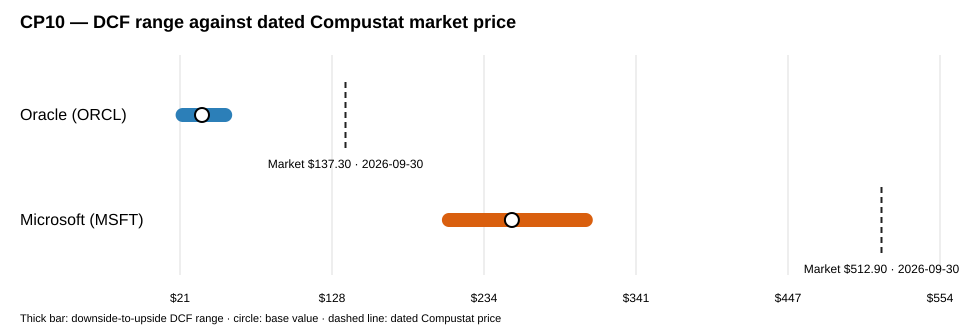

Saved exhibit: /Users/douglasbuckeridge/Documents/Courses/PythonFinance2026/DouglasBuckeridge/lab6/outputs/CP10_two_company_range_exhibit.svg


In [17]:
from IPython.display import SVG, display
from html import escape

def scenario_company(company, margin_shift=0., growth_shift=0.):
    x = deepcopy(company)
    x["drivers"]["gm"] = [v + margin_shift for v in x["drivers"]["gm"]]
    x["drivers"]["growth"] = [v + growth_shift for v in x["drivers"]["growth"]]
    return x

def scenario_values(company):
    # An explicit, rerunnable range: downside / base / upside. Same conventions are used for both firms.
    specs = {"Downside": {"margin_shift": -.02, "growth_shift": -.03},
             "Base": {"margin_shift": 0., "growth_shift": 0.},
             "Upside": {"margin_shift": .02, "growth_shift": .03}}
    out = []
    for case, changes in specs.items():
        c = scenario_company(company, **changes); p = project_company(c); v = valuation(c, p)
        out.append({"case": case, "value_per_share": v["value_per_share"], **changes})
    return pd.DataFrame(out).set_index("case")

orcl_range, msft_range = scenario_values(ORACLE), scenario_values(MSFT)
range_table = pd.DataFrame({"Oracle": orcl_range.value_per_share, "Microsoft": msft_range.value_per_share})
display(range_table.style.format("${:,.2f}"))

if market_prices.empty:
    print("Exhibit values were produced, but the dated-price lines and percentage gaps await the WRDS Compustat pull.")
else:
    price_map = market_prices.set_index("ticker").close_price.to_dict()
    comparison = pd.DataFrame({
        "company": ["Oracle", "Microsoft"], "ticker": ["ORCL", "MSFT"],
        "market_price": [price_map["ORCL"], price_map["MSFT"]],
        "price_date": [market_prices.set_index("ticker").loc["ORCL", "date"], market_prices.set_index("ticker").loc["MSFT", "date"]],
        "low": [orcl_range.loc["Downside", "value_per_share"], msft_range.loc["Downside", "value_per_share"]],
        "base": [orcl_range.loc["Base", "value_per_share"], msft_range.loc["Base", "value_per_share"]],
        "high": [orcl_range.loc["Upside", "value_per_share"], msft_range.loc["Upside", "value_per_share"]],
    })
    for c in ["low", "base", "high"]:
        comparison[f"{c}_gap_pct"] = comparison[c] / comparison.market_price - 1
    display(comparison.style.format({"market_price": "${:,.2f}", "low": "${:,.2f}", "base": "${:,.2f}", "high": "${:,.2f}",
                                     "low_gap_pct": "{:.1%}", "base_gap_pct": "{:.1%}", "high_gap_pct": "{:.1%}"}))
    # Standard-library SVG keeps the exhibit rerunnable even where matplotlib is not installed.
    width, height, left, right = 980, 330, 180, 940
    lo = min(comparison[["low", "market_price"]].min()) * .92
    hi = max(comparison[["high", "market_price"]].max()) * 1.08
    x = lambda value: left + (value - lo) / (hi - lo) * (right - left)
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
           '<rect width="100%" height="100%" fill="white"/>',
           '<text x="20" y="28" font-family="Arial" font-size="18" font-weight="bold">CP10 — DCF range against dated Compustat market price</text>']
    for tick in range(6):
        value, xx = lo + (hi - lo) * tick / 5, left + (right - left) * tick / 5
        svg += [f'<line x1="{xx:.1f}" y1="55" x2="{xx:.1f}" y2="275" stroke="#dddddd"/>',
                f'<text x="{xx:.1f}" y="302" text-anchor="middle" font-family="Arial" font-size="12">${value:,.0f}</text>']
    for pos, row in comparison.reset_index(drop=True).iterrows():
        y, color = 115 + pos * 105, ("#2c7fb8" if pos == 0 else "#d95f0e")
        svg += [f'<text x="20" y="{y+5}" font-family="Arial" font-size="16">{escape(row.company)} ({row.ticker})</text>',
                f'<line x1="{x(row.low):.1f}" y1="{y}" x2="{x(row.high):.1f}" y2="{y}" stroke="{color}" stroke-width="14" stroke-linecap="round"/>',
                f'<circle cx="{x(row.base):.1f}" cy="{y}" r="7" fill="white" stroke="black" stroke-width="2"/>',
                f'<line x1="{x(row.market_price):.1f}" y1="{y-33}" x2="{x(row.market_price):.1f}" y2="{y+33}" stroke="#222" stroke-width="2" stroke-dasharray="6,4"/>',
                f'<text x="{x(row.market_price):.1f}" y="{y+53}" text-anchor="middle" font-family="Arial" font-size="12">Market ${row.market_price:,.2f} · {pd.Timestamp(row.price_date):%Y-%m-%d}</text>']
    svg += ['<text x="20" y="322" font-family="Arial" font-size="11">Thick bar: downside-to-upside DCF range · circle: base value · dashed line: dated Compustat price</text>', '</svg>']
    exhibit_path = LAB / "outputs" / "CP10_two_company_range_exhibit.svg"
    exhibit_path.write_text("\n".join(svg), encoding="utf-8")
    display(SVG(filename=str(exhibit_path))); print(f"Saved exhibit: {exhibit_path}")

## Step 6 — Decision, rerun flip point, and triggers

The next cell calculates a flip point by repeatedly rerunning the model, not by reading a sensitivity-table intersection. It varies only Oracle’s gross-margin driver while holding all other assumptions fixed, and identifies where the two **base-value gaps to their own dated prices** meet. This is the decision metric, so dollar values are never ranked directly. It runs only after CRSP returns both prices.

In [18]:
import numpy as np
def value_gap(company, price):
    return valuation(company, project_company(company))["value_per_share"] / price - 1
if market_prices.empty:
    print("Flip point and decision are PENDING dated professional prices.")
else:
    price_map=market_prices.set_index("ticker").close_price.to_dict()
    base_orcl_gap=value_gap(ORACLE,price_map["ORCL"]); base_msft_gap=value_gap(MSFT,price_map["MSFT"])
    def ranking_difference(gm):
        trial=deepcopy(ORACLE); trial["drivers"]["gm"]=[gm]*5
        try: return value_gap(trial,price_map["ORCL"])-base_msft_gap
        except ValueError as exc:
            if "revolver cap exceeded" in str(exc): return np.nan
            raise
    grid=np.linspace(.40,.95,111)
    results=pd.DataFrame({"oracle_gross_margin":grid,"ranking_difference":[ranking_difference(x) for x in grid]})
    results["feasible"]=results.ranking_difference.notna(); display(results)
    feasible=results[results.feasible].reset_index(drop=True)
    bracket=next(((feasible.loc[i,"oracle_gross_margin"],feasible.loc[i+1,"oracle_gross_margin"]) for i in range(len(feasible)-1) if feasible.loc[i,"ranking_difference"]*feasible.loc[i+1,"ranking_difference"]<=0),None)
    if bracket is None: print("No feasible Oracle gross-margin flip was bracketed; document this or select another single assumption.")
    else:
        lo,hi=bracket; flo=ranking_difference(lo)
        for _ in range(60):
            mid=(lo+hi)/2; fmid=ranking_difference(mid)
            if np.isnan(fmid): lo=mid; continue
            if flo*fmid<=0: hi=mid
            else: lo=mid; flo=fmid
        flip_gm=(lo+hi)/2; winner="Oracle" if base_orcl_gap>base_msft_gap else "Microsoft"; other="Microsoft" if winner=="Oracle" else "Oracle"
        print(f"Recommendation (model output): {winner}; base gaps Oracle {base_orcl_gap:.1%}, Microsoft {base_msft_gap:.1%}.")
        print(
    f"Flip point: Oracle gross margin {flip_gm:.2%}; "
    "above it Oracle ranks higher, and below it Microsoft ranks higher.")
        print(f"Oracle FY2023–25 gross-margin history: {oh['gross margin'].min():.2%} to {oh['gross margin'].max():.2%}; flip is {'inside' if oh['gross margin'].min()<=flip_gm<=oh['gross margin'].max() else 'outside'} history.")

,oracle_gross_margin,ranking_difference,feasible
0,0.40,NaN,False
1,0.41,NaN,False
2,0.41,NaN,False
3,0.42,NaN,False
4,0.42,NaN,False
...,...,...,...
106,0.93,0.29,True
107,0.93,0.30,True
108,0.94,0.32,True
109,0.94,0.33,True


Recommendation (model output): Microsoft; base gaps Oracle -73.2%, Microsoft -50.5%.
Flip point: Oracle gross margin 80.61%; above it Oracle ranks higher, and below it Microsoft ranks higher.
Oracle FY2023–25 gross-margin history: 70.51% to 72.85%; flip is outside history.



### CP10 decision lines

**Recommendation:** Based on the base-case percentage gaps to each company’s dated
Compustat market price, I recommend Microsoft over Oracle. This recommendation holds
while Oracle’s five-year gross-margin assumption remains below approximately **80.61%**,
under the common five-year FCFE horizon and terminal-growth convention.

**Flip point:** The ranking turns on Oracle gross margin. When Oracle’s gross margin is
held at approximately **80.61%**, the rerun cases meet; above that value, Oracle ranks
higher than Microsoft. Oracle’s FY2023–25 gross-margin history was approximately
**70.5% to 72.8%**, so the flip point is outside its recent history.

**Triggers:** For Oracle, I will monitor filed gross margin, calculated as revenue less
filed cost of revenue divided by revenue. If Oracle’s gross margin rises above **80.61%**,
I will re-rank the companies following Oracle’s Q2 FY2027 earnings release on
**December 14, 2026** and confirm the related 10-Q when filed, expected by
**January 9, 2027**.

For Microsoft, I will monitor filed gross margin. If Microsoft’s gross margin falls
below **67.95%**, I will re-rank the companies when Microsoft’s Q1 FY2027 Form 10-Q
is filed, expected by **November 9, 2026**.



## Step 7 — Peer read and CP10 submission record

Peer-read status: I was unable to complete the peer exchange before the checkpoint deadline. My own final review identified three items requiring follow-up:  
1. The dated Compustat price pull was successful and supports the exhibit; however, the Compustat beta query did not return, so the beta inputs remain provisional
2. Oracle’s FY2026 capex/financing path remains incomplete because extending the current capex path exceeds the revolver limit.
3. The recommendation and flip point rely on provisional beta inputs and should be refreshed once the professional-source data pull is available.

**CP10 submission contents:** the saved two-company exhibit (`outputs/CP10_two_company_range_exhibit.svg`) after its Compustat price lines appear; the three finalized decision lines; the actual peer note received; and the AI disclosure below. If a required check or price pull remains unavailable, there is a note  naming the failure and why.

In [19]:
# Professional-source beta control. Run this after market_prices has been populated.
# MANUAL REVIEW: confirm the data window and estimates before using them in the discount rate.
if market_prices.empty:
    print("BETA PENDING: run the WRDS / Compustat price cell first.")
else:
    try:
        import wrds
        beta_user = os.getenv("WRDS_USERNAME")
        if not beta_user:
            beta_user = input("WRDS username for return-based beta pull: ").strip()
        conn = wrds.Connection(wrds_username=beta_user)
        beta_sql = f"""
            select s.tic as ticker, d.datadate, d.trfd, d.sprtrn
            from comp.secd d
            join comp.security s on d.gvkey=s.gvkey and d.iid=s.iid
            where s.tic in ('ORCL','MSFT')
              and d.datadate between ('{PRICE_AS_OF}'::date - interval '2 years') and '{PRICE_AS_OF}'::date
              and d.trfd is not null and d.sprtrn is not null
            order by s.tic, d.datadate
        """
        beta_daily = conn.raw_sql(beta_sql, date_cols=["datadate"])
        conn.close()
        beta_daily["trfd"] = pd.to_numeric(beta_daily["trfd"], errors="coerce")
        beta_daily["sprtrn"] = pd.to_numeric(beta_daily["sprtrn"], errors="coerce")
        beta_daily["stock_return"] = beta_daily.groupby("ticker")["trfd"].pct_change()
        beta_daily = beta_daily.dropna(subset=["stock_return", "sprtrn"])
        beta_estimates = beta_daily.groupby("ticker").apply(
            lambda x: x["stock_return"].cov(x["sprtrn"]) / x["sprtrn"].var()
        ).rename("two_year_daily_beta").reset_index()
        display(beta_estimates)
        beta_estimates.to_csv(LAB / "outputs" / "wrds_compustat_return_betas.csv", index=False)
        print("MANUAL REVIEW: If these estimates are reasonable, copy them into the beta inputs and rerun the fairness, exhibit, and flip-point cells.")
    except Exception as exc:
        print(f"BETA PENDING — retain the error as a documented WRDS attempt: {type(exc).__name__}: {exc}")

WRDS recommends setting up a .pgpass file.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
BETA PENDING — retain the error as a documented WRDS attempt: DatabaseError: Execution failed on sql '
            select s.tic as ticker, d.datadate, d.trfd, d.sprtrn
            from comp.secd d
            join comp.security s on d.gvkey=s.gvkey and d.iid=s.iid
            where s.tic in ('ORCL','MSFT')
              and d.datadate between ('2026-10-01'::date - interval '2 years') and '2026-10-01'::date
              and d.trfd is not null and d.sprtrn is not null
            order by s.tic, d.datadate
        ': (psycopg2.errors.UndefinedColumn) column d.sprtrn does not exist
LINE 2: ...        select s.tic as ticker, d.datadate, d.trfd, d.sprtrn
                                                               ^

[SQL: 
            select s.tic as ticker, d.datadate, d.trfd, d.sprtrn
            from comp.secd d
            join

**CP10 status:** Microsoft FY2026 reproduces and its check block passes. Oracle’s CP9
FY2025 model runs, but its FY2026 update is not yet a completed forecast: carrying
FY2025–26 data-center capex forward causes the revolver cap to be exceeded in FY2030.
The FY2026 Oracle known-answer mapping and a defended capex/financing path remain open.
Beta was a provisional value due to ongoing error in pulling beta values from Wrds. 

## AI disclosure

I used Codex as a coding and workflow assistant for this Lab 6 CP10 notebook. It wrote the code to assemble the notebook and pulled the data from the instructed sources, created the Microsoft company-half swap, format the pro-forma and comparison exhibit, add model checks, and troubleshooted code errors in the WRDS price and flip-point workflow.

I also used ChatGPT Plus to verify my notebook and ensure it met the requirements for the checkpoint. 

I independently ran the notebook, entered and reviewed WRDS outputs, checked filed financial-statement mappings against SEC EDGAR materials, reviewed the assumptions and formulas, and verified the model outputs used in my exhibit and decision lines. I did not use Yahoo Finance or yfinance for filed data, prices, or beta inputs. My Edition A was completed separately by hand in class without AI.

The recommendation, selected trigger thresholds, review dates, and peer feedback are my own judgments based on the model outputs. Oracle’s FY2026 update remains incomplete because carrying the FY2025–26 capex path forward exceeds the modeled revolver capacity; this limitation is stated in the notebook rather than hidden.